In [1]:
pip install tensorflow numpy pandas matplotlib seaborn streamlit pillow scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

# ==========================================
# KONFIGURASI UTAMA & HYPERPARAMETER
# ==========================================
IMG_HEIGHT = 128  # Disarankan 128x128 agar fitur visual organisme laut terpelihara
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 20
DATASET_DIR = r'D:\oceanic-life-classification\OceanLife Dataset' # Sesuaikan dengan path ekstrak dataset Kaggle

# ==========================================
# LANGKAH 1, 2, & 3 — EDA & PRA-PEMROSESAN DATA
# ==========================================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2, # Pembagian 80% Train, 20% Validation/Test
    rotation_range=25,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    DATASET_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    DATASET_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

class_names = list(train_generator.class_indices.keys())
print("Daftar Kelas Organisme:", class_names)

# Save class map to JSON
with open('class_indices.json', 'w') as f:
    json.dump(train_generator.class_indices, f)

Found 2542 images belonging to 10 classes.
Found 630 images belonging to 10 classes.
Daftar Kelas Organisme: ['Coral', 'Crustaceans', 'Fish', 'Jellyfish', 'Octopus', 'Sea Turtle', 'Seaweed', 'Shark', 'Sponges', 'Starfish']


In [19]:
import os

dataset_path = 'D:\oceanic-life-classification\OceanicLife Dataset'

# Mengecek apakah ada subfolder di dalam dataset Anda
if os.path.exists(dataset_path):
    subfolders = [f for f in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, f))]
    if subfolders:
        print("📁 Nama-nama kelas yang terdeteksi di folder Anda:")
        for name in sorted(subfolders):
            print(f"- {name}")
    else:
        print("⚠️ Belum ada subfolder kelas di dalam folder ini (masih berupa file mentah/gambar campur).")
else:
    print("❌ Folder 'OceanicLife Dataset' tidak ditemukan.")

❌ Folder 'OceanicLife Dataset' tidak ditemukan.


<>:3: SyntaxWarning: invalid escape sequence '\o'
<>:3: SyntaxWarning: invalid escape sequence '\o'
C:\Users\user\AppData\Local\Temp\ipykernel_9580\1446880728.py:3: SyntaxWarning: invalid escape sequence '\o'
  dataset_path = 'D:\oceanic-life-classification\OceanicLife Dataset'


In [20]:
import os
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

DATASET_DIR = 'D:\oceanic-life-classification\OceanLife Dataset'

# ==========================================
# TAHAP 1: BERSIHKAN GAMBAR RUSAK/TRUNCATED SECARA TOTAL
# ==========================================
print("🧹 Tahap 1: Memindai dan membuang gambar yang korup/rusak...")
deleted_count = 0

for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
            file_path = os.path.join(root, file)
            try:
                # Izinkan PIL membaca file yang sedikit terpotong dengan aman
                Image.MAX_IMAGE_PIXELS = None
                with Image.open(file_path) as img:
                    img.verify()
                # Cek ulang dengan load beneran
                with Image.open(file_path) as img:
                    img.load()
            except Exception:
                try:
                    os.remove(file_path)
                    deleted_count += 1
                except Exception:
                    pass

print(f"✅ Pembersihan selesai! {deleted_count} file gambar rusak telah dibersihkan.\n")

# ==========================================
# TAHAP 2: KONFIGURASI MODEL & PELATIHAN
# ==========================================
IMG_HEIGHT = 128  
IMG_WIDTH = 128
BATCH_SIZE = 16
EPOCHS = 10

print("🚀 Tahap 2: Menyiapkan Data Generator...")
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    horizontal_flip=True,
    rotation_range=20
)

train_generator = train_datagen.flow_from_directory(
    DATASET_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = train_datagen.flow_from_directory(
    DATASET_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

class_names = list(train_generator.class_indices.keys())
print(f"🎯 Kategori kelas terdeteksi: {class_names}")

# Membangun Arsitektur CNN
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\n🏋️‍♂️ Memulai proses pelatihan model CNN...")
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator
)

# Simpan Model
model.save('oceanic_life_cnn_model.h5')
print("\n🎉 Hore! Pelatihan selesai dan model berhasil disimpan sebagai 'oceanic_life_cnn_model.h5'!")

<>:7: SyntaxWarning: invalid escape sequence '\o'
<>:7: SyntaxWarning: invalid escape sequence '\o'
C:\Users\user\AppData\Local\Temp\ipykernel_9580\1975790865.py:7: SyntaxWarning: invalid escape sequence '\o'
  DATASET_DIR = 'D:\oceanic-life-classification\OceanLife Dataset'


🧹 Tahap 1: Memindai dan membuang gambar yang korup/rusak...
✅ Pembersihan selesai! 3 file gambar rusak telah dibersihkan.

🚀 Tahap 2: Menyiapkan Data Generator...
Found 2540 images belonging to 10 classes.
Found 629 images belonging to 10 classes.
🎯 Kategori kelas terdeteksi: ['Coral', 'Crustaceans', 'Fish', 'Jellyfish', 'Octopus', 'Sea Turtle', 'Seaweed', 'Shark', 'Sponges', 'Starfish']

🏋️‍♂️ Memulai proses pelatihan model CNN...


C:\Users\user\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
 40/159 ━━━━━━━━━━━━━━━━━━━━ 43s 368ms/step - accuracy: 0.4245 - loss: 2.2584

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


159/159 ━━━━━━━━━━━━━━━━━━━━ 75s 461ms/step - accuracy: 0.4394 - loss: 2.0374 - val_accuracy: 0.4515 - val_loss: 1.8531
Epoch 2/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 77s 484ms/step - accuracy: 0.4484 - loss: 1.9101 - val_accuracy: 0.4515 - val_loss: 1.8600
Epoch 3/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 72s 453ms/step - accuracy: 0.4480 - loss: 1.8977 - val_accuracy: 0.4515 - val_loss: 1.8387
Epoch 4/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 74s 468ms/step - accuracy: 0.4480 - loss: 1.8824 - val_accuracy: 0.4515 - val_loss: 1.8674
Epoch 5/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 73s 462ms/step - accuracy: 0.4480 - loss: 1.8922 - val_accuracy: 0.4515 - val_loss: 1.8463
Epoch 6/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 73s 459ms/step - accuracy: 0.4480 - loss: 1.8820 - val_accuracy: 0.4515 - val_loss: 1.8419
Epoch 7/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 76s 475ms/step - accuracy: 0.4480 - loss: 1.8740 - val_accuracy: 0.4515 - val_loss: 1.8552
Epoch 8/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 75s 475ms/step - accuracy: 0.4480 - loss: 1.8615 - val


🎉 Hore! Pelatihan selesai dan model berhasil disimpan sebagai 'oceanic_life_cnn_model.h5'!


In [22]:
# ==========================================
# LANGKAH 5 & 6 — EVALUASI & METRIK
# ==========================================
val_generator.reset()
Y_pred = model.predict(val_generator)
y_pred = np.argmax(Y_pred, axis=1)
y_true = val_generator.classes

# Laporan Klasifikasi (Precision, Recall, F1-Score)
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
df_report = pd.DataFrame(report).transpose()
df_report.to_csv('evaluation_metrics.csv')
print("\nLaporan Evaluasi Model:\n", classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
np.save('confusion_matrix.npy', cm)

# Simpan History Training
history_dict = history.history
with open('training_history.json', 'w') as f:
    json.dump(history_dict, f)

19/40 ━━━━━━━━━━━━━━━━━━━━ 6s 317ms/step

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 288ms/step

Laporan Evaluasi Model:
               precision    recall  f1-score   support

       Coral       0.00      0.00      0.00        28
 Crustaceans       0.00      0.00      0.00        53
        Fish       0.00      0.00      0.00        19
   Jellyfish       0.00      0.00      0.00        45
     Octopus       0.00      0.00      0.00        81
  Sea Turtle       0.45      1.00      0.62       284
     Seaweed       0.00      0.00      0.00        16
       Shark       0.00      0.00      0.00        26
     Sponges       0.00      0.00      0.00        32
    Starfish       0.00      0.00      0.00        45

    accuracy                           0.45       629
   macro avg       0.05      0.10      0.06       629
weighted avg       0.20      0.45      0.28       629



C:\Users\user\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

<>:23: SyntaxWarning: invalid escape sequence '\o'
<>:23: SyntaxWarning: invalid escape sequence '\o'
C:\Users\user\AppData\Local\Temp\ipykernel_9580\2623130690.py:23: SyntaxWarning: invalid escape sequence '\o'
  'D:\oceanic-life-classification\OceanLife Dataset',


Found 629 images belonging to 10 classes.
✅ Grafik konvergensi disimpan sebagai 'training_convergence.png'
19/40 ━━━━━━━━━━━━━━━━━━━━ 5s 247ms/step

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 232ms/step
✅ Confusion matrix disimpan sebagai 'confusion_matrix_plot.png'
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
✅ Visualisasi contoh prediksi disimpan sebagai 'sample_predictions.png'


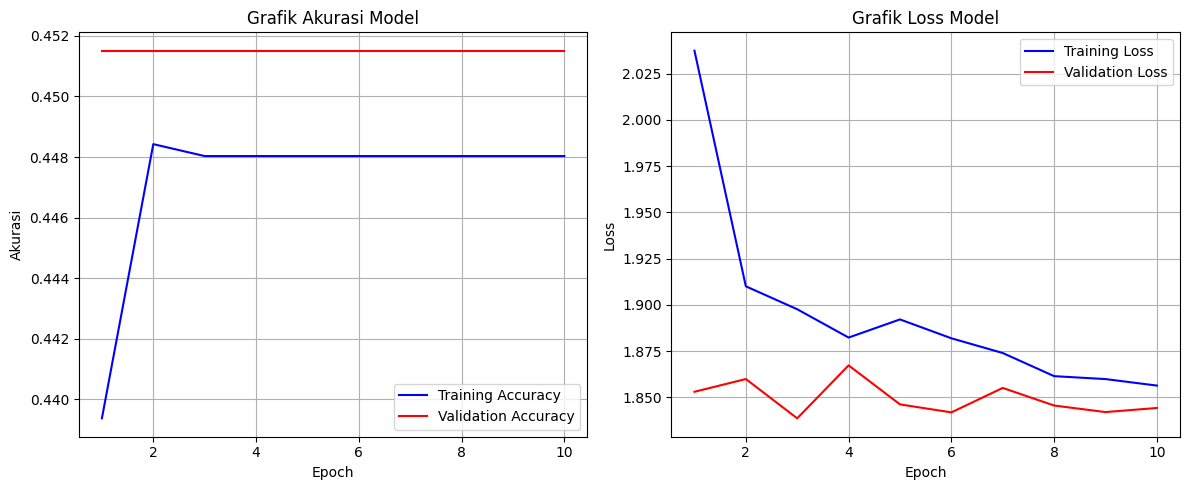

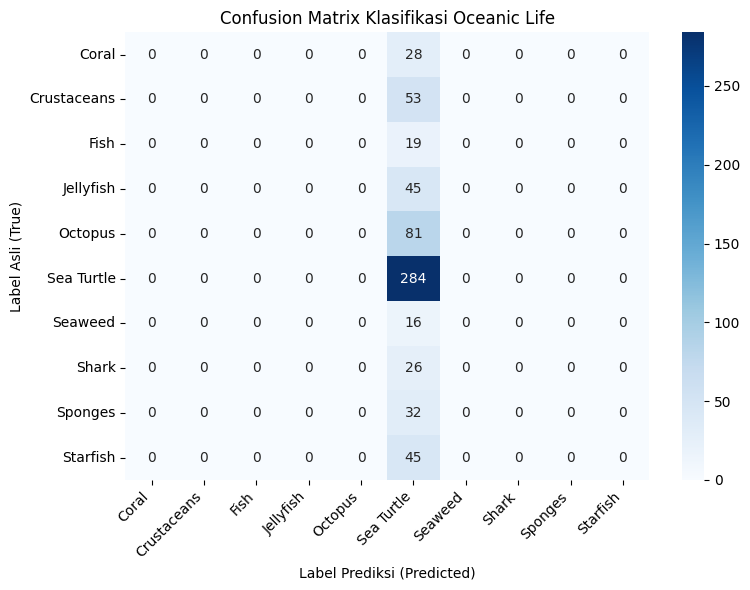

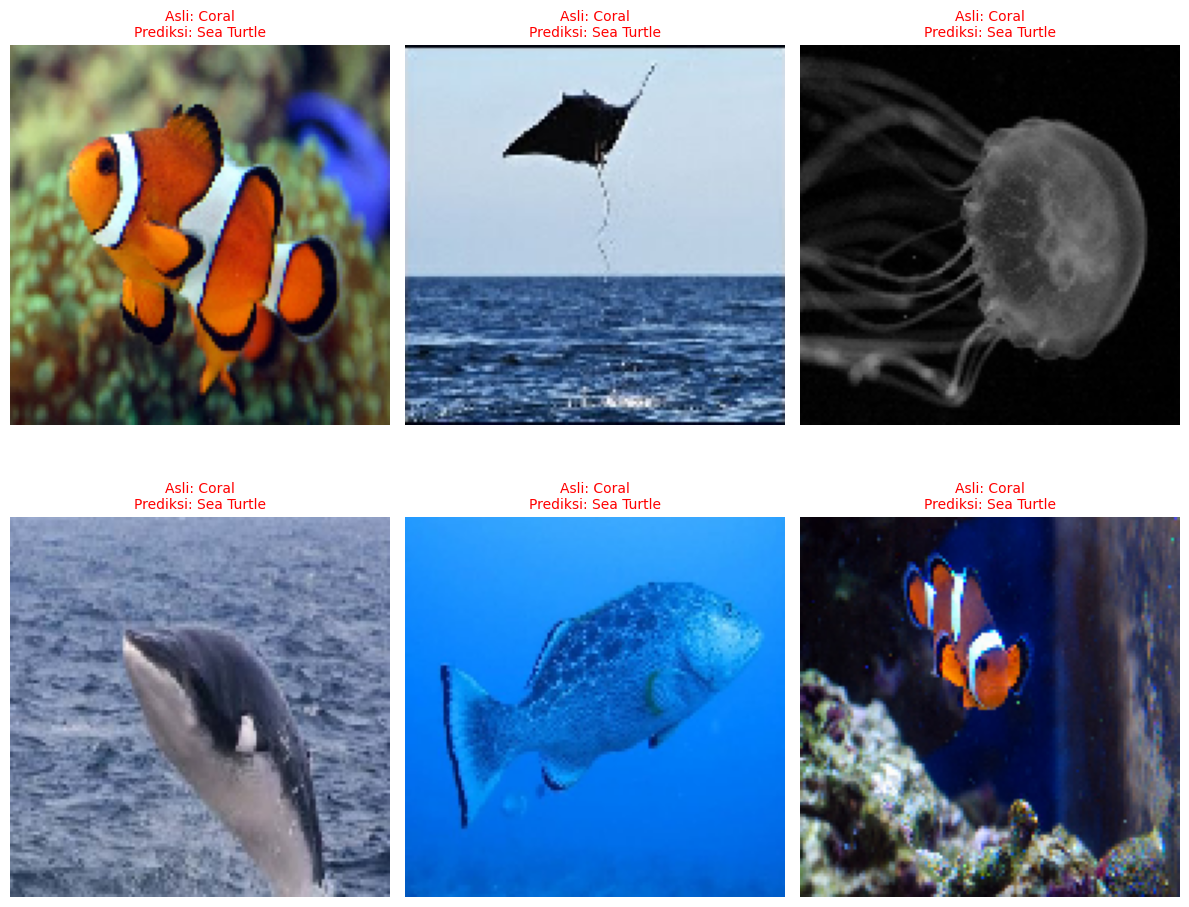

In [24]:
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix

# ==========================================
# 1. LOAD MODEL & DATA VALIDASI
# ==========================================
model = tf.keras.models.load_model('oceanic_life_cnn_model.h5')

with open('class_indices.json', 'r') as f:
    class_indices = json.load(f)
class_names = list(class_indices.keys())

with open('training_history.json', 'r') as f:
    history = json.load(f)

val_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)
val_generator = val_datagen.flow_from_directory(
    'D:\oceanic-life-classification\OceanLife Dataset',
    target_size=(128, 128),
    batch_size=16,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# ==========================================
# 2. GRAFIK AKURASI & LOSS PELATIHAN
# ==========================================
epochs = range(1, len(history['accuracy']) + 1)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, history['accuracy'], 'b-', label='Training Accuracy')
plt.plot(epochs, history['val_accuracy'], 'r-', label='Validation Accuracy')
plt.title('Grafik Akurasi Model')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, history['loss'], 'b-', label='Training Loss')
plt.plot(epochs, history['val_loss'], 'r-', label='Validation Loss')
plt.title('Grafik Loss Model')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('training_convergence.png')
print("✅ Grafik konvergensi disimpan sebagai 'training_convergence.png'")

# ==========================================
# 3. VISUALISASI CONFUSION MATRIX
# ==========================================
val_generator.reset()
Y_pred = model.predict(val_generator)
y_pred = np.argmax(Y_pred, axis=1)
y_true = val_generator.classes

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix Klasifikasi Oceanic Life')
plt.xlabel('Label Prediksi (Predicted)')
plt.ylabel('Label Asli (True)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_matrix_plot.png')
print("✅ Confusion matrix disimpan sebagai 'confusion_matrix_plot.png'")

# ==========================================
# 4. VISUALISASI CONTOH PREDIKSI GAMBAR UJI
# ==========================================
x_batch, y_batch = next(val_generator)
preds = model.predict(x_batch)

plt.figure(figsize=(12, 10))
for i in range(min(6, len(x_batch))):
    plt.subplot(2, 3, i + 1)
    plt.imshow(x_batch[i])
    true_label = class_names[np.argmax(y_batch[i])]
    pred_label = class_names[np.argmax(preds[i])]
    
    color = 'green' if true_label == pred_label else 'red'
    plt.title(f"Asli: {true_label}\nPrediksi: {pred_label}", color=color, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.savefig('sample_predictions.png')
print("✅ Visualisasi contoh prediksi disimpan sebagai 'sample_predictions.png'")

In [14]:
import os
from PIL import Image

DATASET_DIR = 'D:\oceanic-life-classification\OceanLife Dataset'

print("🧹 Memulai pemindaian gambar yang rusak/corrupted...")
deleted_count = 0

# Menelusuri semua folder kelas dan file gambar di dalamnya
for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp', '.webp')):
            file_path = os.path.join(root, file)
            try:
                # Coba buka file gambar menggunakan PIL
                with Image.open(file_path) as img:
                    img.verify() # Memeriksa integritas file gambar
            except (IOError, SyntaxError, OSError) as e:
                print(f"❌ Ditemukan gambar rusak/terpotong: {file_path}")
                try:
                    # Tutup file jika terbuka, lalu hapus
                    os.remove(file_path)
                    deleted_count += 1
                except Exception as del_err:
                    print(f"⚠️ Gagal menghapus file {file_path}: {del_err}")

print("="*40)
print(f"✅ Pembersihan selesai! Total gambar rusak yang dihapus: {deleted_count}")
print("Sekarang kamu bisa menjalankan ulang skrip pelatihan model.")

<>:4: SyntaxWarning: invalid escape sequence '\o'
<>:4: SyntaxWarning: invalid escape sequence '\o'
C:\Users\user\AppData\Local\Temp\ipykernel_9580\739980647.py:4: SyntaxWarning: invalid escape sequence '\o'
  DATASET_DIR = 'D:\oceanic-life-classification\OceanLife Dataset'


🧹 Memulai pemindaian gambar yang rusak/corrupted...
✅ Pembersihan selesai! Total gambar rusak yang dihapus: 0
Sekarang kamu bisa menjalankan ulang skrip pelatihan model.


In [10]:
import os

DATASET_DIR = 'D:\oceanic-life-classification\OceanicLife Dataset'

if os.path.exists(DATASET_DIR):
    print("Isi folder OceanicLife Dataset:")
    for item in os.listdir(DATASET_DIR):
        print("-", item)
else:
    print("Wah, foldernya gak ketemu.")

Isi folder OceanicLife Dataset:
- 001v5h0d.jpg
- 002ojjl6.jpg
- 00dx9zud.JPG
- 00gohyw5.jpg
- 00lvn4tu.gif
- 015e0ase.jpg
- 015us06k.jpg
- 017s6334.jpeg
- 01cqbman.jpg
- 01fifu6i.jpg
- 01ji8io2.jpg
- 01ly8g4q.jpg
- 01n1y044.jpg
- 01ov0jbm.jpg
- 01r93u21.jpg
- 01xiaw2o.jpg
- 02tr376x.jpg
- 02vexi3e.jpg
- 030ec6l6.jpg
- 03hrvmyq.jpg
- 03inzepu.jpg
- 04bcs2eh.jpg
- 04rl38td.jpg
- 04xgr3pc.jpg
- 052plo3c.jpg
- 05fgym44.jpg
- 05upaxf4.jpg
- 05v2gfd5.jpg
- 05woe4jx.jpg
- 05x522he.jpg
- 061jgn5z.jpg
- 06b0zot4.jpg
- 06i3c3qg.jpg
- 06tv8q6n.jpg
- 06xhbl8g.jpg
- 070p2pfr.jpg
- 073et61f.jpeg
- 078rt3hu.jpg
- 07hv702k.jpg
- 07xsi3ku.jpg
- 082chjsb.jpg
- 083w4ggf.jpg
- 088qtrzz.jpg
- 08k6qtny.jpg
- 091b4vx1.jpg
- 094s9x5s.png
- 09em27n0.jpg
- 09enmc54.jpg
- 09jtzksm.jpg
- 09nvfjal.jpg
- 09zkkoru.jpg
- 0aozzfjx.jpg
- 0aszooyd.jpg
- 0ave39n4.jpg
- 0awquf3u.jpg
- 0b9rzkzk.jpg
- 0b9wozxe.jpg
- 0bdz3bx5.jpg
- 0bjnoveh.jpg
- 0bp217nr.jpeg
- 0bs6x3t4.JPG
- 0btudsvf.jpg
- 0bty378h.jpg
- 0bw5ai4n.jpg
- 0c0

<>:3: SyntaxWarning: invalid escape sequence '\o'
<>:3: SyntaxWarning: invalid escape sequence '\o'
C:\Users\user\AppData\Local\Temp\ipykernel_9580\2247633993.py:3: SyntaxWarning: invalid escape sequence '\o'
  DATASET_DIR = 'D:\oceanic-life-classification\OceanicLife Dataset'
